# Finding User Usage Patterns with Machine Learning

We use KMeans clustering to split alarm-app users into **usage patterns (personas)** without supervision.
Rather than relying on ground-truth labels, we formalize "*how* users use the service" from a combination of
features, interpret and name each cluster from its centroid, and then link it to a key metric (retention)
to get all the way to an action.

Practice flow:
- **8.5.2.** Building user features — 8.5.2.1 Extracting user features (feature-engineering SQL that encodes domain knowledge) · 8.5.2.2 Checking feature distributions (do they discriminate between users?)
- **8.5.3.** Feature scaling + choosing the number of clusters (Elbow · Silhouette)
- **8.5.4.** Clustering — 8.5.4.1 Reading characteristics from centroids → persona naming · 8.5.4.2 Visualizing clusters with PCA
- **8.5.5.** Using clustering with cohorts and metrics — 8.5.5.1 Clustering new and existing users separately · 8.5.5.2 Retention KPI by cluster → linking to actions · 8.5.5.3 Loading labels & saving/loading the model

> The example data is synthetic, built by "planting" four personas. Follow along and check whether KMeans
> recovers those personas almost exactly.

## 8.5.1. Preparing the practice data

If you don't have the data yet, first run `python generate_data.py` to generate the example data
(`data/alarm_daily.csv`, `data/user_master.csv`). The first cell below installs the dependencies.
Running the notebook to the end also produces per-user cluster labels (`output/`) and KMeans model files (`models/`).

The two tables used in this practice are:

- `alarm_daily.csv` — per-user, per-day alarm usage log. `local_date` (usage date), `user_id`, `scheduled_cnt` (number of alarms set that day),
  `first_scheduled_min` · `last_scheduled_min` (time of the first/last alarm, in minutes since midnight — e.g. 382 = 06:22), `snooze_alarm_cnt` (number of alarms snoozed),
  `mission_used_cnt` (number of alarms that used a mission), `mission_attempt_cnt` (number of mission attempts), `total_time_to_dismiss` (total time until the alarms were dismissed, minutes),
  `first_ring_to_last_dismiss` (time from the first ring to the last dismissal = time it took to get up, minutes)
- `user_master.csv` — one row per user. `user_id`, `new_flag` (whether the user is new), `retained_d7` (whether the user was retained on day 7).
  Used for the cohort split in 8.5.5.1 and for linking the retention KPI in 8.5.5.2.

In [1]:
# Install dependencies (skips quickly if they are already installed)
# The %pip magic installs into the current kernel environment, so it works without PATH issues.
%pip install -q -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pickle, os
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

con = duckdb.connect()

# --- Shared chart style for the book (unified palette, grid, spines) ---
PALETTE = ["#1f9d78", "#3b4556", "#d97706", "#6b7380"]  # green, slate, amber, muted
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.alpha": 0.3,
    "figure.dpi": 150, "legend.frameon": False,
})

## 8.5.2. Building user features

### 8.5.2.1. Extracting user features

Alongside the obvious per-user alarm count, we extract features such as total wake-up time, snooze ratio and mission ratio,
and apply a simple clipping rule to remove outliers. The domain knowledge emphasized in the theory section is baked right into this SQL: we filter to weekdays (Mon–Fri) only,
suppress day-to-day noise by averaging over the period, and build features one level deeper — alarm count, interval,
wake-up time, missions and so on. For the clustering input we keep a separate `_cluster` version with extreme values clipped.
(Same query as `sql/extract_features.sql`)

The code starts by letting DuckDB work with the CSV files directly in SQL. First we register a view that turns the daily log into daily derived metrics, and a clip macro that cuts off extreme values.

In [3]:
con.execute("""
CREATE OR REPLACE MACRO clip(x, lim, cap) AS CASE WHEN x > lim THEN cap ELSE x END;  -- clip extreme values

-- Daily alarm log -> daily derived metrics. Weekdays (Mon-Fri) only (weekday and weekend patterns differ sharply)
CREATE OR REPLACE VIEW daily_stat AS
  SELECT local_date, user_id, scheduled_cnt,
         (last_scheduled_min - first_scheduled_min) / NULLIF(scheduled_cnt - 1, 0) AS avg_interval,
         snooze_alarm_cnt      / scheduled_cnt AS avg_snooze,
         mission_used_cnt      / scheduled_cnt AS used_mission_per_alarm,
         mission_attempt_cnt   / scheduled_cnt AS mission_attempt_per_alarm,
         total_time_to_dismiss / scheduled_cnt AS avg_time_to_dismiss,
         first_ring_to_last_dismiss
  FROM read_csv_auto('data/alarm_daily.csv')
  WHERE isodow(CAST(local_date AS DATE)) BETWEEN 1 AND 5   -- DuckDB isodow: Mon=1
    AND scheduled_cnt > 0
    AND first_ring_to_last_dismiss > 0
""")

Now we average over the period per user, and build the clipped version (_cluster) for the clustering input alongside.

In [4]:
query = """
WITH user_features AS (   -- suppress day-to-day noise by averaging over the period
  SELECT user_id,
         AVG(scheduled_cnt)                AS scheduled_cnt,
         AVG(COALESCE(avg_interval, 0))    AS avg_interval,
         AVG(avg_snooze)                   AS avg_snooze,
         AVG(used_mission_per_alarm)       AS used_mission_per_alarm,
         AVG(mission_attempt_per_alarm)    AS mission_attempt_per_alarm,
         AVG(avg_time_to_dismiss)          AS avg_time_to_dismiss,
         AVG(first_ring_to_last_dismiss)   AS first_ring_to_last_dismiss
  FROM daily_stat
  GROUP BY user_id
)
SELECT m.new_flag, m.retained_d7, u.*,
       -- Clustering input: version with extreme values clipped -- clip(value, limit, replacement)
       clip(scheduled_cnt, 10, 11)                AS scheduled_cnt_cluster,
       clip(avg_interval, 60, 65)                 AS avg_interval_cluster,
       clip(avg_snooze, 10, 11)                   AS avg_snooze_cluster,
       clip(used_mission_per_alarm, 10, 11)       AS used_mission_cluster,
       clip(mission_attempt_per_alarm, 10, 11)    AS mission_attempt_cluster,
       clip(avg_time_to_dismiss, 120, 125)        AS avg_time_to_dismiss_cluster,
       clip(first_ring_to_last_dismiss, 120, 125) AS first_ring_to_last_dismiss_cluster
FROM user_features AS u
LEFT JOIN read_csv_auto('data/user_master.csv') AS m USING (user_id)
ORDER BY user_id
"""
df = con.execute(query).df()
print("users:", len(df))
df.head()

users: 2400


,new_flag,retained_d7,user_id,scheduled_cnt,avg_interval,avg_snooze,used_mission_per_alarm,mission_attempt_per_alarm,avg_time_to_dismiss,first_ring_to_last_dismiss,scheduled_cnt_cluster,avg_interval_cluster,avg_snooze_cluster,used_mission_cluster,mission_attempt_cluster,avg_time_to_dismiss_cluster,first_ring_to_last_dismiss_cluster
0,False,False,u00001,1.6,15.00,1.000000,1.000000,1.400000,68.940000,74.77,1.6,15.00,1.000000,1.000000,1.400000,68.940000,74.77
1,False,False,u00002,1.4,7.45,0.750000,0.916667,1.450000,67.641667,75.49,1.4,7.45,0.750000,0.916667,1.450000,67.641667,75.49
2,False,False,u00003,1.4,6.75,0.966667,1.000000,1.283333,67.498333,74.51,1.4,6.75,0.966667,1.000000,1.283333,67.498333,74.51
3,False,False,u00004,1.9,15.55,1.000000,0.950000,1.300000,67.601667,76.41,1.9,15.55,1.000000,0.950000,1.300000,67.601667,76.41
4,False,False,u00005,1.2,4.70,1.000000,0.900000,1.150000,68.475000,75.49,1.2,4.70,1.000000,0.900000,1.150000,68.475000,75.49


### 8.5.2.2. Checking feature distributions

We check the distributions to ask "does this feature actually reveal differences between users?" A feature on which
every user has roughly the same value has no discriminating power, so we skim the histograms once before feeding
anything into the clustering.

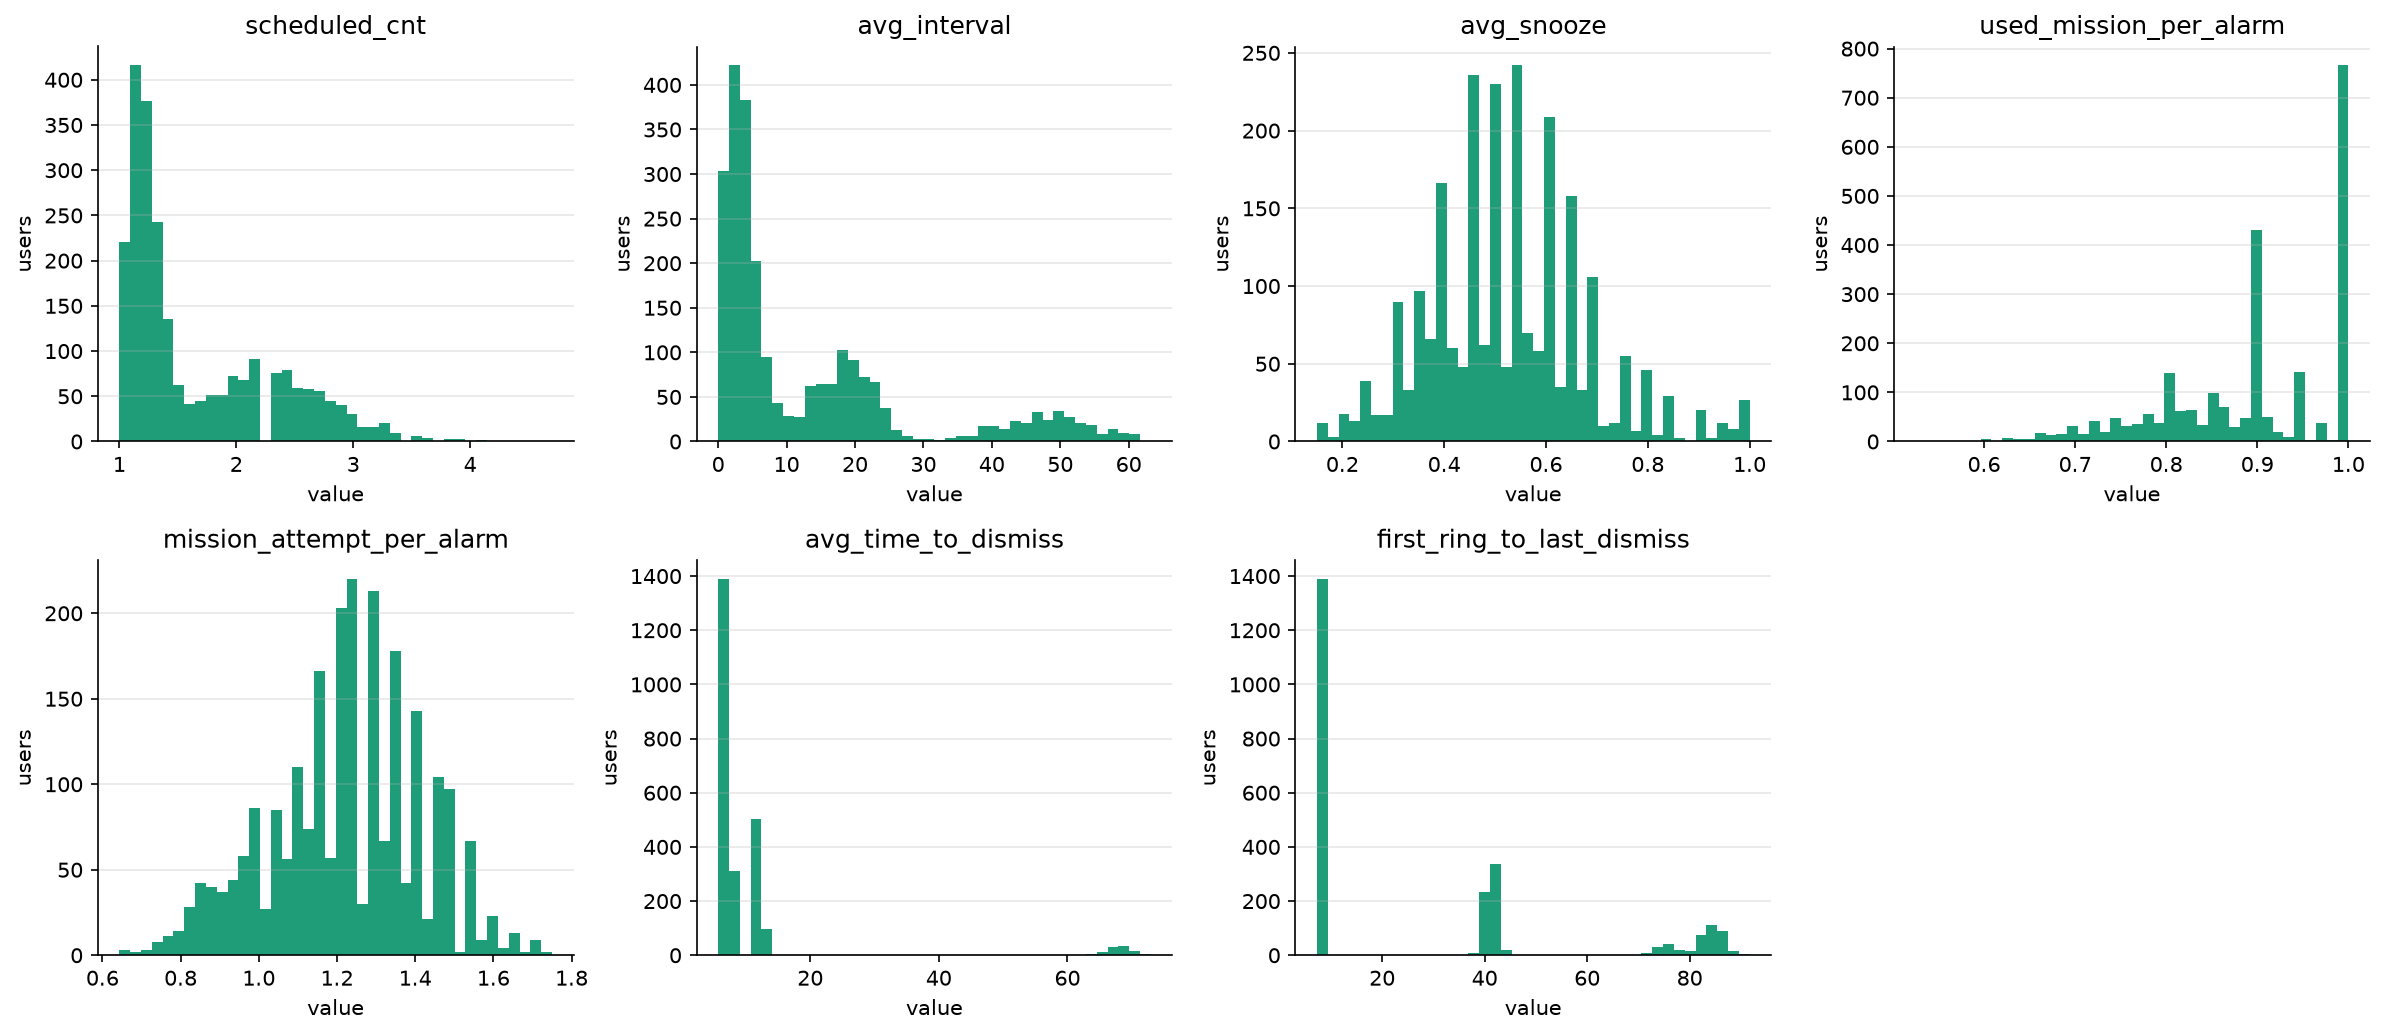

In [5]:
# Check each feature's distribution for discriminating power between users (if everyone looks the same, it is useless for separating clusters)
feat_cols = ['scheduled_cnt', 'avg_interval', 'avg_snooze',
             'used_mission_per_alarm', 'mission_attempt_per_alarm',
             'avg_time_to_dismiss', 'first_ring_to_last_dismiss']

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), feat_cols):
    ax.hist(df[col].dropna(), bins=40, color='#1f9d78')
    ax.set_title(col); ax.set_xlabel('value'); ax.set_ylabel('users')
axes.ravel()[-1].set_visible(False)   # 7 features -> hide the empty panel
plt.tight_layout(); plt.show()

## 8.5.3. Feature scaling + choosing the number of clusters

**Why do we need scaling?** KMeans splits points into clusters by Euclidean distance.
But `first_ring_to_last_dismiss` (wake-up time, 0–120 minutes) and `avg_snooze` (snoozes per alarm, roughly 0–1)
differ in scale by a factor of tens to a hundred. Fed in as-is, the wide-range feature would monopolize the distance
calculation, and we would effectively be clustering on a single feature. `StandardScaler` standardizes each feature
to mean 0 and standard deviation 1 so that every feature contributes equally.

In [6]:
# Clustering input: use only the _cluster features with extreme values clipped
cluster_cols = [c for c in df.columns if c.endswith('_cluster')]
X = df[cluster_cols].dropna()

# Standardize (mean 0, std 1): keeps large-scale features from monopolizing the distance calculation in distance-based KMeans
scaler = StandardScaler().fit(X)
X_scaled = scaler.transform(X)

print('clustering features:', [c.replace('_cluster', '') for c in cluster_cols])
print('X shape:', X_scaled.shape)

clustering features: ['scheduled_cnt', 'avg_interval', 'avg_snooze', 'used_mission', 'mission_attempt', 'avg_time_to_dismiss', 'first_ring_to_last_dismiss']
X shape: (2400, 7)


Now we plot the Elbow Method (inertia) and the Silhouette score together to choose the number of clusters `k`.
The Elbow looks for the point where the slope of the inertia curve bends; the Silhouette looks for the point where
cluster separation is sharpest. We also weigh a practical criterion: "a number of clusters the team can understand and manage."

Using the standardized matrix, we vary k from 1 to 10 and plot the Elbow (inertia) and Silhouette scores side by side.

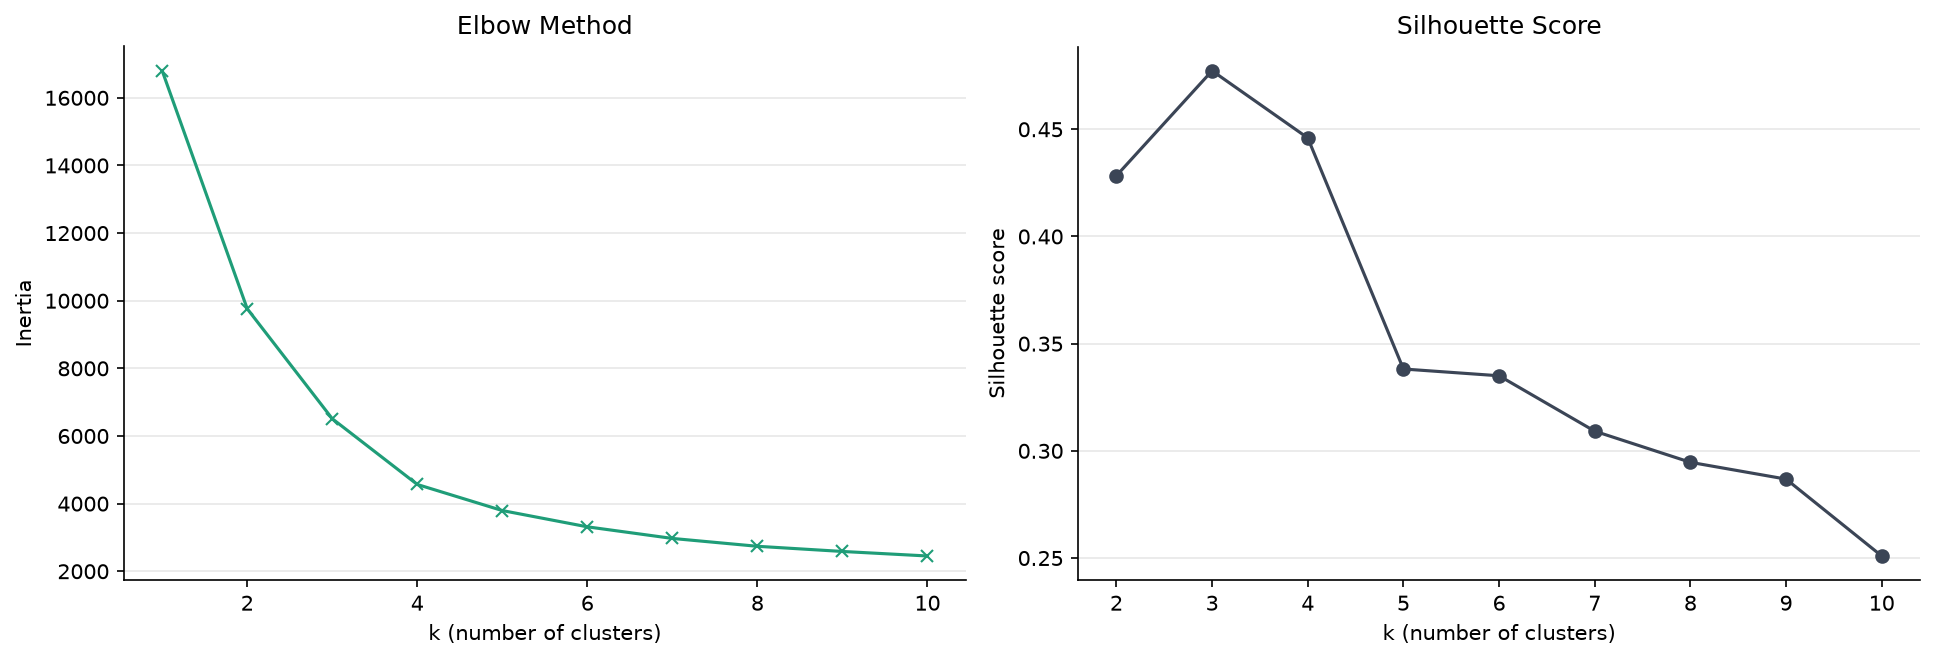

In [7]:
# Vary k from 1 to 10 and measure inertia (within-cluster sum of squared distances) -> the point where the slope bends is the Elbow
k_values = range(1, 11)
inertias = [KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled).inertia_
            for k in k_values]

# silhouette: how well separated the clusters are (-1 to 1, higher is better)
sil_values = range(2, 11)
silhouettes = [silhouette_score(X_scaled, KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled).labels_)
               for k in sil_values]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
ax1.plot(list(k_values), inertias, 'x-', color='#1f9d78')
ax1.set_xlabel('k (number of clusters)'); ax1.set_ylabel('Inertia'); ax1.set_title('Elbow Method')
ax2.plot(list(sil_values), silhouettes, 'o-', color='#3b4556')
ax2.set_xlabel('k (number of clusters)'); ax2.set_ylabel('Silhouette score'); ax2.set_title('Silhouette Score')
plt.tight_layout(); plt.show()

## 8.5.4. Clustering

### 8.5.4.1. Reading characteristics from centroids

In this example we check whether the clusters we saw in the main text (Table 8.1 · Table 8.2) are recovered cleanly.
We fit KMeans with the `k` chosen above, gather the centroid that represents each cluster into one table to read off its characteristics, and then verify once more with the visualization in 8.5.4.2.
Centroids live in the standardized space, so we map them back to the **original units (minutes, counts)** with
`scaler.inverse_transform` to make the interpretation sharper. KMeans is a centroid-based algorithm, so the centroid *is* the representative pattern of its cluster.

In [8]:
def fit_kmeans(frame, k=4):
    # Scale -> KMeans -> map centroids back to original units. Reused as-is in 8.5.5.1 (new vs. existing comparison)
    # Also return the scaler used for training, so new data can be transformed on the same basis
    cols = [c for c in frame.columns if c.endswith('_cluster')]
    X = frame[cols].dropna()
    scaler = StandardScaler().fit(X)
    model = KMeans(n_clusters=k, random_state=42, n_init=10).fit(scaler.transform(X))
    centers = pd.DataFrame(scaler.inverse_transform(model.cluster_centers_),
                           columns=[c.replace('_cluster', '') for c in cols])
    return model, scaler, X, model.labels_, centers

k = 4
kmeans, scaler, X, raw_labels, centers = fit_kmeans(df, k)

# Name the personas by reading the centroids (alarm count = minimalist/maximalist, wake-up time = weak-willed or not)
PERSONA_ORDER = ['Weak-willed Minimalist', 'Minimalist', 'Weak-willed Maximalist', 'Trying Maximalist']
def name_persona(r):
    if r['scheduled_cnt'] < 2:                                  # ~1 alarm = minimalist
        return 'Weak-willed Minimalist' if r['first_ring_to_last_dismiss'] > 40 else 'Minimalist'
    return 'Weak-willed Maximalist' if r['first_ring_to_last_dismiss'] > 60 else 'Trying Maximalist'
centers['persona'] = centers.apply(name_persona, axis=1)

KMeans label numbers are assigned arbitrarily on every run, so we remap them to 0–3 in persona order, then attach readable headers and shares to build a summary table.

In [9]:
# KMeans label numbers are arbitrary, so remap them to 0-3 in persona order (PERSONA_ORDER)
centers['cluster'] = centers['persona'].map({n: i for i, n in enumerate(PERSONA_ORDER)})
labels = pd.Series(raw_labels).map(dict(zip(centers.index, centers['cluster']))).to_numpy()

# Attach the labels to df for the later steps (PCA, retention)
df_labeled = df.loc[X.index].copy()
df_labeled['cluster'] = labels

# Tidy the summary table with readable headers + shares
DISPLAY = {'scheduled_cnt': 'Alarms', 'avg_interval': 'Interval between alarms (min)',
           'avg_snooze': 'Snoozes per alarm', 'used_mission': 'Missions used per alarm',
           'mission_attempt': 'Mission attempts per alarm', 'avg_time_to_dismiss': 'Time to dismiss (min)',
           'first_ring_to_last_dismiss': 'First ring to last dismiss (min)'}
summary = centers.set_index('cluster').sort_index().rename(columns=DISPLAY)
summary.insert(0, 'persona', summary.pop('persona'))
summary['Count'] = pd.Series(labels).value_counts()
summary['share'] = (summary['Count'] / summary['Count'].sum() * 100).map('{:.2f}%'.format)
summary[list(DISPLAY.values())] = summary[list(DISPLAY.values())].round(2)
summary

,persona,Alarms,Interval between alarms (min),Snoozes per alarm,Missions used per alarm,Mission attempts per alarm,Time to dismiss (min),First ring to last dismiss (min),Count,share
cluster,,,,,,,,,,
0,Weak-willed Minimalist,1.40,8.58,0.91,0.91,1.28,68.09,75.15,99,4.12%
1,Minimalist,1.19,3.14,0.52,0.95,1.31,6.21,8.41,1390,57.92%
2,Weak-willed Maximalist,2.80,47.88,0.39,0.78,0.91,8.35,84.48,312,13.00%
3,Trying Maximalist,2.17,18.42,0.55,0.82,1.16,11.93,40.41,599,24.96%


Reading the centroid table reveals the regularized user patterns. We named the four personas by alarm count
(minimalist/maximalist) and wake-up time (weak-willed or not) (cluster numbers are sorted 0–3 to match Table 8.1 · Table 8.2 in the main text):

- **0. Weak-willed Minimalist** — ~1 alarm, ~9-minute interval, yet snoozes often, always uses a mission, ~68 minutes to dismiss and ~75 minutes to get up. The smallest group (4.12%).
- **1. Minimalist** — ~1 alarm, ~3-minute interval, snoozes half the time, always uses a mission, gets up quickly (~8 minutes). The largest cluster (57.92%).
- **2. Weak-willed Maximalist** — ~3 alarms with a very long interval (~48 minutes), rarely snoozes and uses missions less, dismisses in ~8 minutes but takes ~84 minutes to get up.
- **3. Trying Maximalist** — ~2 alarms, ~18-minute interval, snoozes half the time, always uses a mission, ~12 minutes to dismiss and ~40 minutes to get up.

For an analyst, a summary at this level is already enough to come up with action items — nudge cluster 0, which takes a long time to dismiss, toward setting more alarms,
and try a stronger wake-up mission or a paid feature on cluster 2, which sets many alarms yet still can't get up.
But rather than listing numbers, giving the cluster a persona name — "this cluster is the *Weak-willed Minimalist*" —
makes it far easier to communicate with PMs, designers and other stakeholders. If naming is hard, naming them
together with your teammates is a good approach too.

### 8.5.4.2. Visualizing clusters with PCA

We reduce the 7 features to two dimensions (PCA) to see the size and boundaries of the clusters with our own eyes.

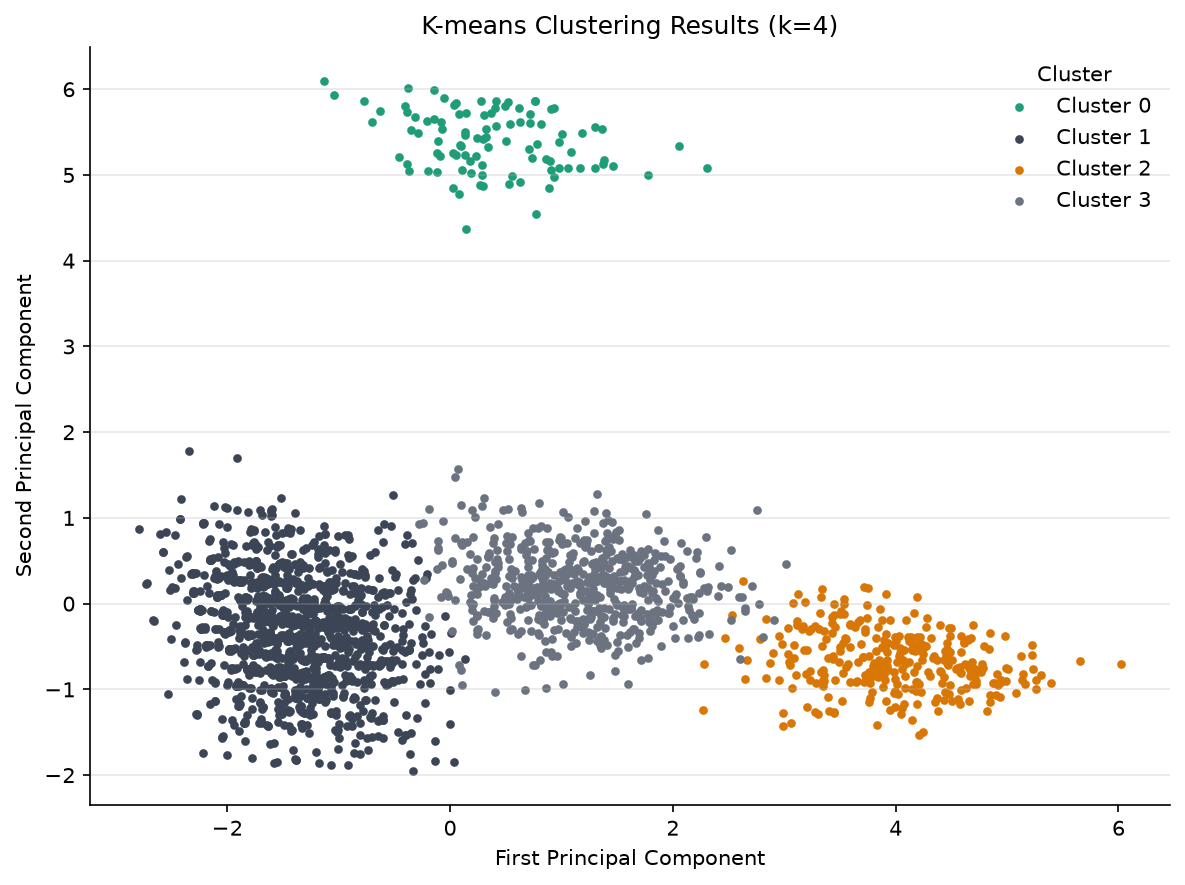

In [10]:
# Project the 7 features onto 2 dimensions (PCA) to eyeball cluster size and boundaries
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

fig, ax = plt.subplots(figsize=(8, 6))
for c in sorted(set(labels)):
    mask = labels == c
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1], s=10, label=f'Cluster {c}')
ax.set_xlabel('First Principal Component'); ax.set_ylabel('Second Principal Component')
ax.set_title(f'K-means Clustering Results (k={k})'); ax.legend(title='Cluster')
plt.tight_layout(); plt.show()

## 8.5.5. Using clustering with cohorts and metrics

### 8.5.5.1. Clustering new and existing users separately

If the service already has a criterion that separates users (here, `new_flag`), you can split the groups and
cluster each one separately to compare differences in usage patterns. Going further, you can track which
existing-user cluster new users move into over time, to observe behavioral change.
The repeated fit-and-summarize steps are wrapped in a function (scaling is handled inside too).

Even though this is example data, you can see that new and existing users share similar patterns while the proportions between groups differ.
Note, however, that KMeans label numbers are arbitrary for each model, so when comparing the new/existing outputs you have to match **the same patterns by centroid values**,
not by number — in the output below, new users' cluster 0 and existing users' cluster 1 are the same Minimalist pattern.

In [11]:
def summarize(centers, labels):   # centroid table + user counts
    out = centers.round(2); out.index.name = 'Cluster'
    out['count'] = pd.Series(labels).value_counts().sort_index()
    return out

# Apply the same procedure (fit_kmeans) to new and existing users separately and compare the pattern mix
df_new = df[df.new_flag == True]
model_new, scaler_new, X_new, labels_new, centers_new = fit_kmeans(df_new)
df_new = df_new.loc[X_new.index].copy(); df_new['label'] = labels_new

df_old = df[df.new_flag == False]
model_old, scaler_old, X_old, labels_old, centers_old = fit_kmeans(df_old)
df_old = df_old.loc[X_old.index].copy(); df_old['label'] = labels_old

print('New-user cluster centroids'); display(summarize(centers_new, labels_new))
print('Existing-user cluster centroids'); summarize(centers_old, labels_old)

New-user cluster centroids


,scheduled_cnt,avg_interval,avg_snooze,used_mission,mission_attempt,avg_time_to_dismiss,first_ring_to_last_dismiss,count
Cluster,,,,,,,,
0,1.19,3.15,0.52,0.95,1.30,6.28,8.81,335
1,2.78,47.49,0.39,0.78,0.91,8.35,84.31,184
2,1.50,10.33,0.90,0.88,1.28,68.26,75.62,18
3,2.18,18.59,0.55,0.82,1.15,12.03,41.09,301


Existing-user cluster centroids


,scheduled_cnt,avg_interval,avg_snooze,used_mission,mission_attempt,avg_time_to_dismiss,first_ring_to_last_dismiss,count
Cluster,,,,,,,,
0,1.38,8.19,0.91,0.92,1.28,68.05,75.05,81
1,1.19,3.13,0.52,0.95,1.32,6.18,8.25,1055
2,2.83,48.44,0.38,0.78,0.92,8.36,84.72,128
3,2.18,18.28,0.56,0.82,1.17,11.85,39.82,298


### 8.5.5.2. Retention KPI by cluster → linking to actions

Instead of stopping at splitting the clusters, we profile each cluster's **key metric** to define
"the usage patterns that help our service most." In an alarm app, retention is the metric that feeds
directly into DAU. Here we look at D7 retention by cluster.

> Note: retention is **not a clustering input**. We use it only as a metric for evaluating the unsupervised
> clusters *after the fact* (split the patterns first, free of label bias, then interpret).

Compare the clusters with the highest and lowest retention, and you can propose action items that use the high-performing group as a seed to grow that cluster.
That said, you cannot conclude that a specific behavior of the high-retention cluster is the direct 'cause' of retention,
so frame it as a clear hypothesis and verify it with an experiment such as an A/B test.

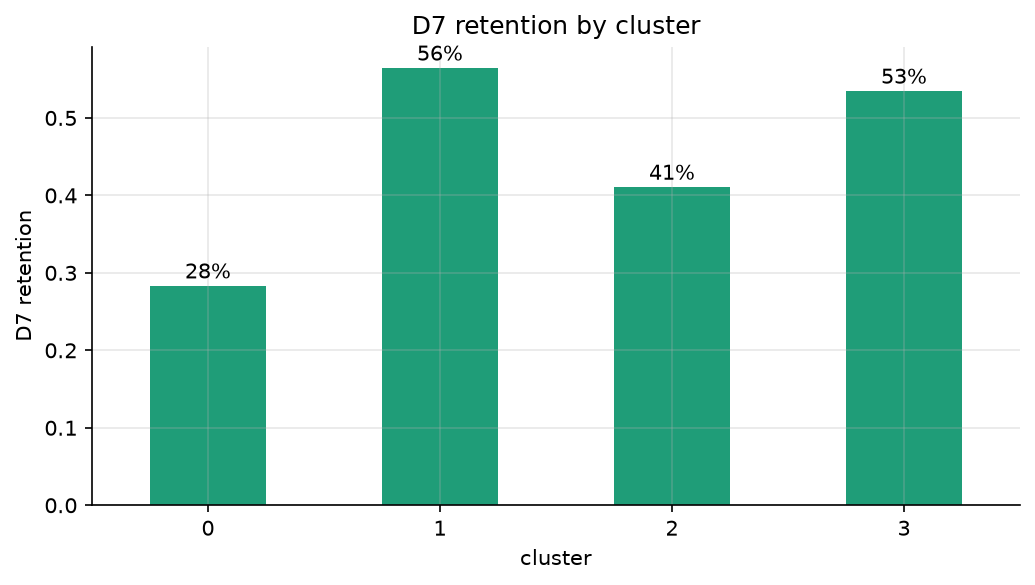

cluster
0    0.283
1    0.564
2    0.410
3    0.534
Name: retained_d7, dtype: float64

Best-retained cluster: 1 (56%) - you could propose actions that use this persona as a seed to grow it.


In [12]:
# Retention is not a clustering input; it is a metric for evaluating the unsupervised clusters 'after the fact'
retention = df_labeled.groupby('cluster')['retained_d7'].mean().sort_index()

fig, ax = plt.subplots(figsize=(7, 4))
retention.plot.bar(ax=ax, color='#1f9d78')
ax.set_xlabel('cluster'); ax.set_ylabel('D7 retention'); ax.set_title('D7 retention by cluster')
plt.xticks(rotation=0)
for i, v in enumerate(retention):
    ax.text(i, v + 0.01, f'{v:.0%}', ha='center')
plt.tight_layout(); plt.show()

print(retention.round(3))
print('\nBest-retained cluster:', int(retention.idxmax()),
      f'({retention.max():.0%}) - you could propose actions that use this persona as a seed to grow it.')

### 8.5.5.3. Loading labels & saving/loading the model

Once you judge the clusters to be meaningful, store the per-user labels and keep the model as a file.
Label numbers here are relative to each model (new/existing), so the same 0 means a different pattern in the two groups;
we store `new_flag` alongside the label to tell which model it came from. This way you can keep quantifying user patterns
on the same basis over time and manage the user journey. (Here the labels are saved to a local CSV.)

One thing to be careful about, though. The KMeans model was trained in the standardized space, so to feed new user data into this model later you must transform it with the very same StandardScaler used in training. If you save only the model, that transformation basis is lost — so we recommend pickling the scaler object together with it.

In [13]:
os.makedirs('output', exist_ok=True); os.makedirs('models', exist_ok=True)

# Load the new/existing labels together (a local CSV stands in for loading a table in a real service)
df_all = pd.concat([df_new, df_old])[['user_id', 'new_flag', 'label']]
df_all.to_csv('output/user_labels.csv', index=False)
print(f'saved {len(df_all):,} labels -> output/user_labels.csv')

# Save the model together with the scaler as a pickle -- so the next analysis assigns labels on the same basis
for model, scaler, path in [(model_new, scaler_new, 'models/kmeans_new_user.pkl'),
                            (model_old, scaler_old, 'models/kmeans_old_user.pkl')]:
    pickle.dump({'scaler': scaler, 'model': model}, open(path, 'wb')); print(f'Model saved to {path}')

# Reload consistency check: transform with the saved scaler before predicting, and the same labels are reproduced
loaded = pickle.load(open('models/kmeans_new_user.pkl', 'rb'))
relabels = loaded['model'].predict(loaded['scaler'].transform(X_new))
print('reloaded model clusters:', loaded['model'].n_clusters,
      '| label reproduction match:', f"{(relabels == labels_new).mean():.0%}")

saved 2,400 labels -> output/user_labels.csv
Model saved to models/kmeans_new_user.pkl
Model saved to models/kmeans_old_user.pkl
reloaded model clusters: 4 | label reproduction match: 100%


## Wrapping up — interpretation matters as much as technique

The value of a KMeans result ultimately depends on the interpretation and insight attached to it. However good
the result, if the team doesn't buy into it, it never turns into real action. Packaging results in a form your
audience can easily grasp, like persona naming, and connecting them to a key metric like retention to propose
"so what do we do" — that is a data analyst's skill that matters as much as the technique.